# 04 — Advanced Exploratory Data Analysis

## Purpose
Notebooks 01–03 established **what the data is** (inventory, keys, relationships, data quality). This notebook asks **what the data says about the business**: how sales evolve, how customers buy, which products and categories carry revenue, and how delivery relates to customer satisfaction. Statistical inference (confidence intervals, hypothesis tests, models) follows in notebook 05.

## Inputs and rules
- **Data:** the validated Gold star schema (`data/processed/analytical/`), the same tables that feed the PostgreSQL warehouse and the dbt marts. Nothing is recomputed from raw data.
- **Revenue (Q-03):** item-based (`items_price_total`, prices only, excluding freight) and payment-based amounts are never mixed. This notebook uses item-based revenue unless stated otherwise.
- **Time (Q-11):** trend and seasonality analyses use the candidate window 2017-01 to 2018-08. The months outside it are near-empty.
- **Delivery (D-06):** delivery metrics use delivered orders that have a delivery date.
- **Reviews (Q-04 / D-07):** delivery-vs-review analyses use eligible orders with **exactly one review that is not shared with another order**. Each review then belongs to exactly one order, and no order-level score is invented.

## Questions
1. What does a typical order look like, and how extreme are the tails?
2. How do volume and revenue evolve, and is there weekly or event seasonality?
3. How concentrated is revenue across products, sellers and customers?
4. How do customers buy: frequency, repurchase timing, geography?
5. Which categories drive revenue, volume and price levels?
6. How do delivery speed and punctuality relate to review scores?
7. Which order attributes move together (multivariate view)?

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd
import plotly.express as px
import plotly.io as pio
import seaborn as sns
from plotly.subplots import make_subplots
from statsmodels.tsa.seasonal import STL

pio.renderers.default = "notebook_connected"
sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
GOLD = ROOT / "data" / "processed" / "analytical"
read = lambda t: pd.read_parquet(GOLD / f"{t}.parquet")
orders, lines, payments, reviews = (read(t) for t in ("fact_orders", "fact_order_lines", "fact_payments", "fact_reviews"))
customers, products = read("dim_customers"), read("dim_products")

# guard: these are the validated Gold baselines (strategy 11.3.3)
counts = {"orders": len(orders), "lines": len(lines), "payments": len(payments), "reviews": len(reviews), "persons": len(customers)}
assert counts == {"orders": 99_441, "lines": 102_425, "payments": 103_886, "reviews": 99_224, "persons": 96_096}, counts

# IBGE macro-regions, the same mapping as the approved query delivery_region_ranking
REGION = {**dict.fromkeys(["AC", "AP", "AM", "PA", "RO", "RR", "TO"], "Norte"),
          **dict.fromkeys(["AL", "BA", "CE", "MA", "PB", "PE", "PI", "RN", "SE"], "Nordeste"),
          **dict.fromkeys(["DF", "GO", "MT", "MS"], "Centro-Oeste"),
          **dict.fromkeys(["ES", "MG", "RJ", "SP"], "Sudeste"), **dict.fromkeys(["PR", "RS", "SC"], "Sul")}
REGION_ORDER = ["Sudeste", "Sul", "Centro-Oeste", "Nordeste", "Norte"]
orders["region"] = orders["customer_state_std"].map(REGION)
assert orders["region"].notna().all()

window = orders[orders["in_candidate_window"]]
eligible = orders[(orders["order_status"] == "delivered") & orders["order_delivered_customer_date"].notna()]   # D-06
one_review = eligible[eligible["review_count"] == 1]
rv = reviews[reviews["order_id"].isin(one_review["order_id"]) & ~reviews["dq_review_id_shared"]]
reviewed = one_review.merge(rv[["order_id", "review_score", "dq_review_before_delivery"]], on="order_id", validate="1:1")
reviewed["low_review"] = reviewed["review_score"] <= 2
print(counts)
print(f"window orders {len(window):,} | D-06 eligible {len(eligible):,} | eligible with one unshared review {len(reviewed):,}")

{'orders': 99441, 'lines': 102425, 'payments': 103886, 'reviews': 99224, 'persons': 96096}
window orders 99,092 | D-06 eligible 96,470 | eligible with one unshared review 94,430


## 1. Univariate analysis
### 1.1 Order value (item-based)
**Question:** what is a typical order, and how heavy is the upper tail?

,order value (BRL)
orders,"98,666.000"
mean,137.754
median,86.900
std,210.645
coef. of variation,1.529
skewness,9.728
excess kurtosis,266.067
p90,269.900
p99,998.900
max,"13,440.000"


IQR outliers on the raw scale: 7,913 (8.0%) | on the log scale: 1,492 (1.51%)
top 1% of orders carry 11.6% of item revenue


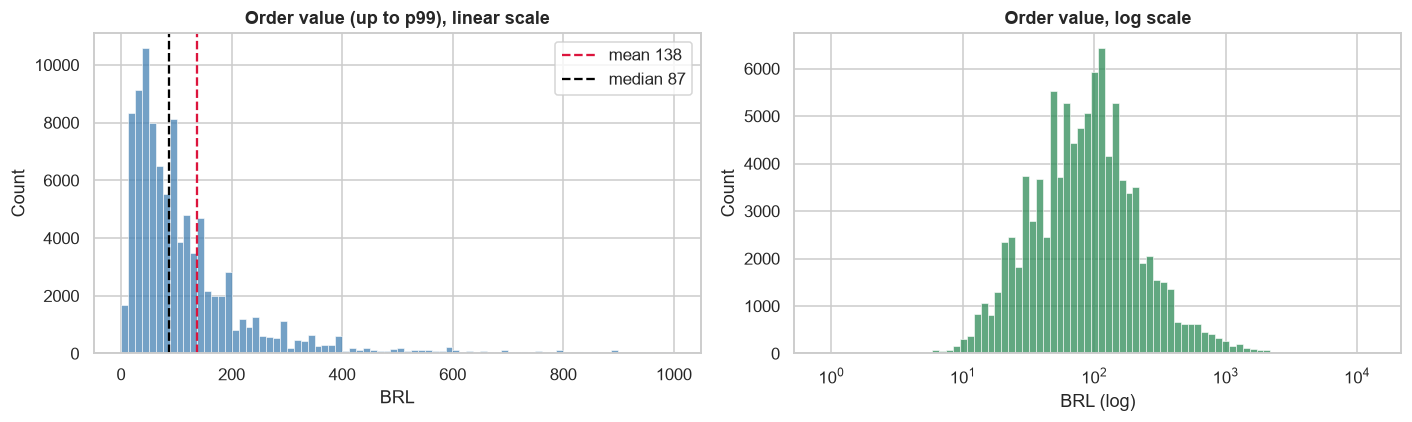

In [2]:
ov = orders.loc[orders["has_items"], "items_price_total"]
desc = pd.Series({"orders": len(ov), "mean": ov.mean(), "median": ov.median(), "std": ov.std(),
                  "coef. of variation": ov.std() / ov.mean(), "skewness": ov.skew(), "excess kurtosis": ov.kurt(),
                  "p90": ov.quantile(.90), "p99": ov.quantile(.99), "max": ov.max()})
display(desc.to_frame("order value (BRL)"))

def iqr_outliers(x):
    q1, q3 = np.percentile(x, [25, 75]); fence = 1.5 * (q3 - q1)
    return int(((x < q1 - fence) | (x > q3 + fence)).sum())
print(f"IQR outliers on the raw scale: {iqr_outliers(ov):,} ({iqr_outliers(ov) / len(ov):.1%}) | "
      f"on the log scale: {iqr_outliers(np.log(ov)):,} ({iqr_outliers(np.log(ov)) / len(ov):.2%})")
print(f"top 1% of orders carry {ov[ov >= ov.quantile(.99)].sum() / ov.sum():.1%} of item revenue")

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(ov[ov <= ov.quantile(.99)], bins=80, ax=ax[0], color="steelblue")
for v, c, lbl in ((ov.mean(), "crimson", "mean"), (ov.median(), "black", "median")):
    ax[0].axvline(v, color=c, ls="--", label=f"{lbl} {v:,.0f}")
ax[0].set(title="Order value (up to p99), linear scale", xlabel="BRL"); ax[0].legend()
sns.histplot(ov, bins=80, log_scale=True, ax=ax[1], color="seagreen")
ax[1].set(title="Order value, log scale", xlabel="BRL (log)")
plt.tight_layout(); plt.show()

**Interpretation.** Order value is strongly right-skewed:
- The mean (138 BRL) is 1.6× the median (87 BRL), and the standard deviation (211 BRL) is larger than the mean (coefficient of variation 1.53).
- Skewness is 9.7 and excess kurtosis 266, so the tail is very heavy.

On the raw scale the IQR rule flags 8.0% of orders as outliers, but on the log scale only 1.5%. The "outliers" are mostly the ordinary upper tail of a log-normal-like distribution, not anomalies. This agrees with notebook 03, which found the extremes corroborated by payments.

The top 1% of orders carry 11.6% of item revenue. **Consequences:**
- Report the median, or the mean together with its confidence interval, as the typical basket.
- Use log-scale or rank-based methods for inference (notebook 05).
- Never trim the large orders, because they are real revenue.

### 1.2 Review scores, delivery time and freight share

review score shares (%): {1: 11.5, 2: 3.2, 3: 8.2, 4: 19.3, 5: 57.8}
delivery days: median 10.2, mean 12.6, p90 23.1, p99 46.1
vs estimate: early 91.9%, on the estimated day 1.3%, late 6.8%; median -12 days
freight share of order value: median 18.3%, p90 38.4%


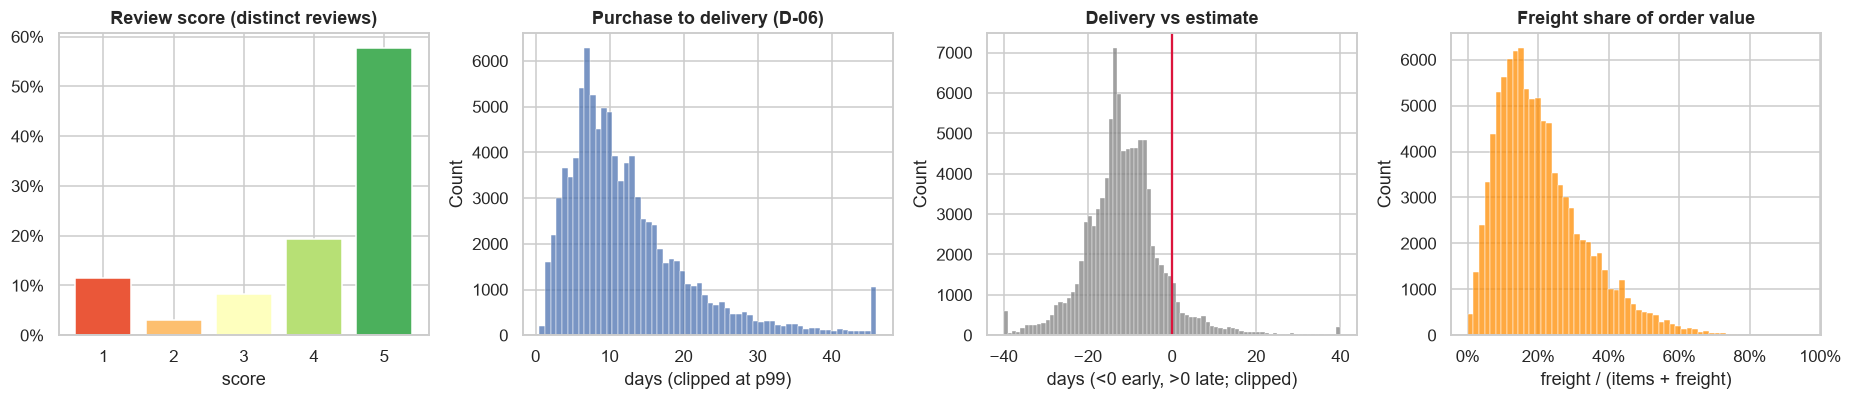

In [3]:
scores = reviews.drop_duplicates("review_id")["review_score"].value_counts(normalize=True).sort_index()   # one row per review (D-07)
delay = eligible["delivery_vs_estimate_days"]
days = eligible["purchase_to_delivery_days"]
fshare = (orders["items_freight_total"] / (orders["items_price_total"] + orders["items_freight_total"]))[orders["has_items"]]

print("review score shares (%):", {int(k): round(float(v) * 100, 1) for k, v in scores.items()})
print(f"delivery days: median {days.median():.1f}, mean {days.mean():.1f}, p90 {days.quantile(.9):.1f}, p99 {days.quantile(.99):.1f}")
print(f"vs estimate: early {(delay < 0).mean():.1%}, on the estimated day {(delay == 0).mean():.1%}, late {(delay > 0).mean():.1%}; "
      f"median {delay.median():.0f} days")
print(f"freight share of order value: median {fshare.median():.1%}, p90 {fshare.quantile(.9):.1%}")

fig, ax = plt.subplots(1, 4, figsize=(17, 3.8))
ax[0].bar(scores.index, scores.values, color=sns.color_palette("RdYlGn", 5)); ax[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[0].set(title="Review score (distinct reviews)", xlabel="score")
sns.histplot(days.clip(upper=days.quantile(.99)), bins=60, ax=ax[1]); ax[1].set(title="Purchase to delivery (D-06)", xlabel="days (clipped at p99)")
sns.histplot(delay.clip(-40, 40), bins=80, ax=ax[2], color="gray"); ax[2].axvline(0, color="crimson")
ax[2].set(title="Delivery vs estimate", xlabel="days (<0 early, >0 late; clipped)")
sns.histplot(fshare, bins=60, ax=ax[3], color="darkorange"); ax[3].xaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[3].set(title="Freight share of order value", xlabel="freight / (items + freight)")
plt.tight_layout(); plt.show()

**Interpretation.**
- **Review scores are J-shaped:** 57.8% are 5 stars and 11.5% are 1 star, with few in between. Satisfaction is polarised, so "share of 1–2 star reviews" is a more informative target than the mean score.
- **Delivery estimates are very conservative.** 91.9% of eligible orders arrive before the estimated date (median 12 days early), and only 6.8% are late. The promised date protects punctuality at the cost of a long promise. The actual median delivery is 10.2 days, with a long tail (p99 46 days).
- **Freight is a large cost component:** the median freight share is 18.3% of order value, and for 1 order in 10 it exceeds 38%.

## 2. Temporal trends and seasonality
### 2.1 Monthly volume and item revenue (candidate window)

In [4]:
monthly = window.groupby("purchase_year_month").agg(orders=("order_id", "size"), item_revenue=("items_price_total", "sum"))
monthly["avg_order_value"] = monthly["item_revenue"] / window[window["has_items"]].groupby("purchase_year_month").size()
fig = make_subplots(specs=[[{"secondary_y": True}]])
fig.add_bar(x=monthly.index, y=monthly["orders"], name="orders", marker_color="lightsteelblue")
fig.add_scatter(x=monthly.index, y=monthly["item_revenue"], name="item revenue (BRL)", mode="lines+markers", secondary_y=True)
fig.update_layout(title="Monthly orders and item revenue, 2017-01 to 2018-08", height=380, legend=dict(orientation="h"))
fig.show()

ytd = lambda y: window[window["purchase_year_month"].between(f"{y}-01", f"{y}-08")]
g_orders = len(ytd(2018)) / len(ytd(2017)) - 1
g_rev = ytd(2018)["items_price_total"].sum() / ytd(2017)["items_price_total"].sum() - 1
print(f"Jan-Aug 2018 vs Jan-Aug 2017: orders {g_orders:+.1%}, item revenue {g_rev:+.1%}")
print(f"average order value by month: min {monthly['avg_order_value'].min():.0f}, max {monthly['avg_order_value'].max():.0f} BRL")
display(monthly.tail(8))

Jan-Aug 2018 vs Jan-Aug 2017: orders +135.1%, item revenue +137.3%
average order value by month: min 125, max 152 BRL


,orders,item_revenue,avg_order_value
purchase_year_month,,,
2018-01,7269,"950,030.360",131.583
2018-02,6728,"844,178.710",126.110
2018-03,7211,"983,213.440",136.785
2018-04,6939,"996,647.750",143.733
2018-05,6873,"996,517.680",145.413
2018-06,6167,"865,124.310",140.442
2018-07,6292,"895,507.220",142.756
2018-08,6512,"854,686.330",132.468


**Interpretation.**
- **Growth:** the business more than doubled. Comparing January–August 2018 with January–August 2017, orders are up 135% and item revenue up 137%.
- **Basket size is stable:** the average order value only ranged between 125 and 152 BRL per month. Growth therefore came from **more orders, not larger baskets**.
- **2018 has plateaued:** volume was flat from January to August 2018, at roughly 6,200–7,300 orders a month.
- **Caveat:** the figures cover the marketplace's own data window. Growth may reflect platform expansion (more sellers and channels), not like-for-like demand.

### 2.2 Daily orders: trend, weekly seasonality and events (STL decomposition)

STL strength: trend 0.73, weekly seasonality 0.22 (0 = none, 1 = all)
largest days: {Timestamp('2017-11-24 00:00:00'): 1176, Timestamp('2017-11-25 00:00:00'): 499, Timestamp('2017-11-27 00:00:00'): 403, Timestamp('2017-11-26 00:00:00'): 391, Timestamp('2017-11-28 00:00:00'): 380}
largest STL residuals (unexplained by trend + weekday): {Timestamp('2017-11-24 00:00:00'): 920.0, Timestamp('2017-11-25 00:00:00'): 288.0, Timestamp('2017-11-26 00:00:00'): 149.0, Timestamp('2018-05-15 00:00:00'): 102.0}


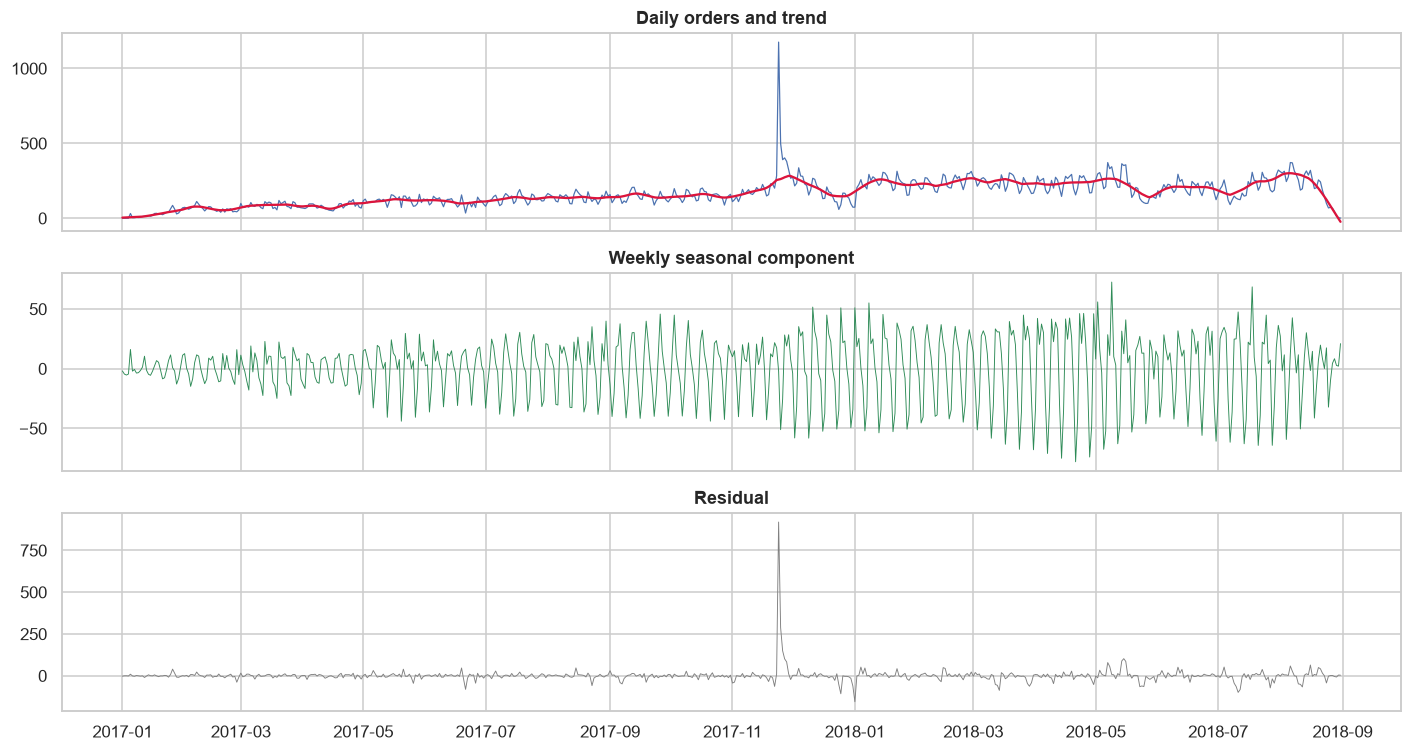

In [5]:
daily = (window.groupby("purchase_date").size()
         .reindex(pd.date_range("2017-01-01", "2018-08-31", freq="D"), fill_value=0).rename("orders"))
stl = STL(daily, period=7, robust=True).fit()
var = lambda s: float(np.var(s))
seasonal_strength = max(0.0, 1 - var(stl.resid) / var(stl.seasonal + stl.resid))
trend_strength = max(0.0, 1 - var(stl.resid) / var(stl.trend + stl.resid))
print(f"STL strength: trend {trend_strength:.2f}, weekly seasonality {seasonal_strength:.2f} (0 = none, 1 = all)")
print("largest days:", daily.nlargest(5).to_dict())
print("largest STL residuals (unexplained by trend + weekday):", stl.resid.nlargest(4).round(0).to_dict())

fig, ax = plt.subplots(3, 1, figsize=(13, 7), sharex=True)
ax[0].plot(daily, lw=.8); ax[0].plot(stl.trend, color="crimson", lw=1.5); ax[0].set_title("Daily orders and trend")
ax[1].plot(stl.seasonal, lw=.6, color="seagreen"); ax[1].set_title("Weekly seasonal component")
ax[2].plot(stl.resid, lw=.6, color="gray"); ax[2].set_title("Residual")
plt.tight_layout(); plt.show()

**Interpretation.** The STL decomposition (period 7) separates three things:
- **A dominant trend** (strength 0.73).
- **Moderate weekly seasonality** (strength 0.22).
- **One event:** Black Friday (2017-11-24), with 1,176 orders. That is about 920 orders above trend plus weekday, roughly 4.6× the volume expected for that day, and the effect persisted at a lower level over the following weekend and Monday.

Apart from this cluster and one smaller spike (2018-05-15), the residuals are unremarkable. For forecasting, model Black Friday as an explicit event, not as noise, and expect weekday effects.

### 2.3 When during the week do customers buy?

share of orders by weekday: {'Monday': 16.3, 'Tuesday': 16.0, 'Wednesday': 15.6, 'Thursday': 14.8, 'Friday': 14.2, 'Saturday': 10.9, 'Sunday': 12.0}
orders 10:00-21:59: 75.7% | 00:00-06:59: 5.3%


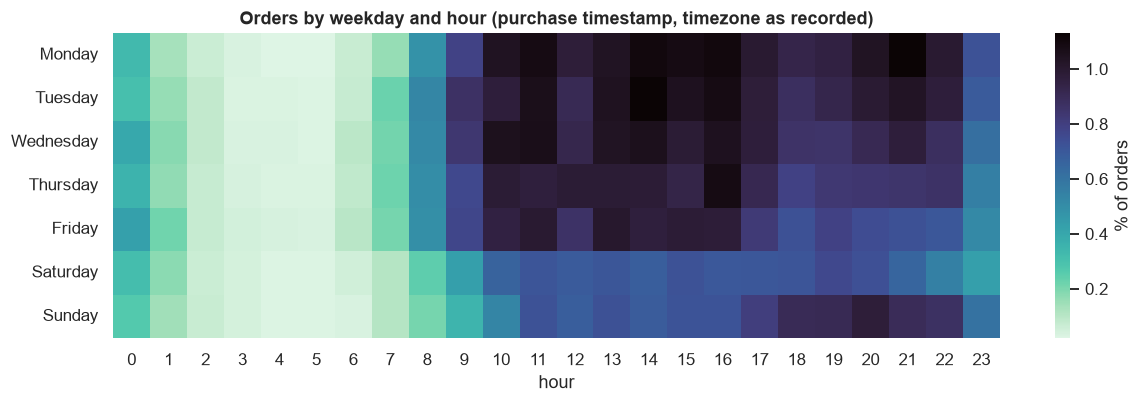

In [6]:
ts = window["order_purchase_timestamp"]
heat = pd.crosstab(ts.dt.day_name(), ts.dt.hour, normalize=True).reindex(
    ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"])
by_day = heat.sum(axis=1)
print("share of orders by weekday:", (by_day * 100).round(1).to_dict())
print(f"orders 10:00-21:59: {heat.loc[:, 10:21].values.sum():.1%} | 00:00-06:59: {heat.loc[:, 0:6].values.sum():.1%}")
plt.figure(figsize=(13, 3.6))
sns.heatmap(heat * 100, cmap="mako_r", cbar_kws={"label": "% of orders"})
plt.title("Orders by weekday and hour (purchase timestamp, timezone as recorded)"); plt.xlabel("hour"); plt.ylabel("")
plt.show()

**Interpretation.**
- **Weekdays:** buying peaks Monday to Wednesday (about 16% of orders each). Saturday is the weakest day (10.9%).
- **Hours:** 75.7% of orders are placed between 10:00 and 21:59, and only 5.3% between 00:00 and 06:59.
- **Implications:** campaigns and customer-service capacity are best aligned with weekday daytime. The quiet early-morning hours suit batch processing.
- **Caveat:** the source timezone is unknown (Q-14), so the hours are as recorded.

## 3. Revenue concentration
**Question:** how much of item revenue depends on a small share of products, sellers and customers?

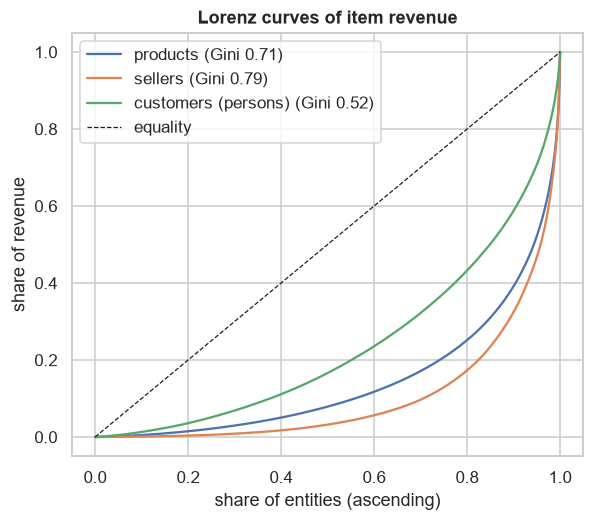

,count,gini,top 10% share,top 1% share
entity,,,,
products,32951,0.709,0.608,0.245
sellers,3095,0.792,0.675,0.257
customers (persons),95420,0.522,0.412,0.115


In [7]:
def lorenz(values):
    v = np.sort(np.asarray(values, dtype=float)); n = len(v)
    cum = np.concatenate([[0], np.cumsum(v) / v.sum()])
    gini = (2 * np.sum(np.arange(1, n + 1) * v)) / (n * v.sum()) - (n + 1) / n
    return np.linspace(0, 1, n + 1), cum, gini

entities = {"products": lines.groupby("product_id")["line_price_total"].sum(),
            "sellers": lines.groupby("seller_id")["line_price_total"].sum(),
            "customers (persons)": lines.groupby("customer_unique_id")["line_price_total"].sum()}
rows = []
fig, ax = plt.subplots(figsize=(6, 5))
for name, s in entities.items():
    x, y, g = lorenz(s)
    top10 = s.nlargest(max(1, len(s) // 10)).sum() / s.sum()
    rows.append({"entity": name, "count": len(s), "gini": g, "top 10% share": top10,
                 "top 1% share": s.nlargest(max(1, len(s) // 100)).sum() / s.sum()})
    ax.plot(x, y, label=f"{name} (Gini {g:.2f})")
ax.plot([0, 1], [0, 1], "k--", lw=.8, label="equality")
ax.set(title="Lorenz curves of item revenue", xlabel="share of entities (ascending)", ylabel="share of revenue"); ax.legend()
plt.show()
display(pd.DataFrame(rows).set_index("entity"))

**Interpretation.** Revenue is highly concentrated on the supply side:
- **Sellers:** Gini 0.79. The top 10% of sellers carry 67.5% of item revenue, and the top 1% (30 sellers) carry 25.7%.
- **Products:** Gini 0.71. The top 10% of products carry 60.8%.
- **Customers:** spend is less concentrated (Gini 0.52; the top 10% of people carry 41.2%), which fits the mostly one-off buying in section 4.

**Business implication:** seller retention and the health of the top sellers is a concentration risk. Losing a few dozen sellers would remove a quarter of revenue. On the demand side the revenue base is broad.

## 4. Customer purchasing behaviour
### 4.1 Frequency and time to the second order

persons 96,096; repeat customers 3.12%; orders per person: {1: 93099, 2: 2745, 3: 203, 4: 30, 5: 8}
time to second order (n=2,997): same day 30.9%, within 30 days 51.1%, median 28 days, mean 80 days


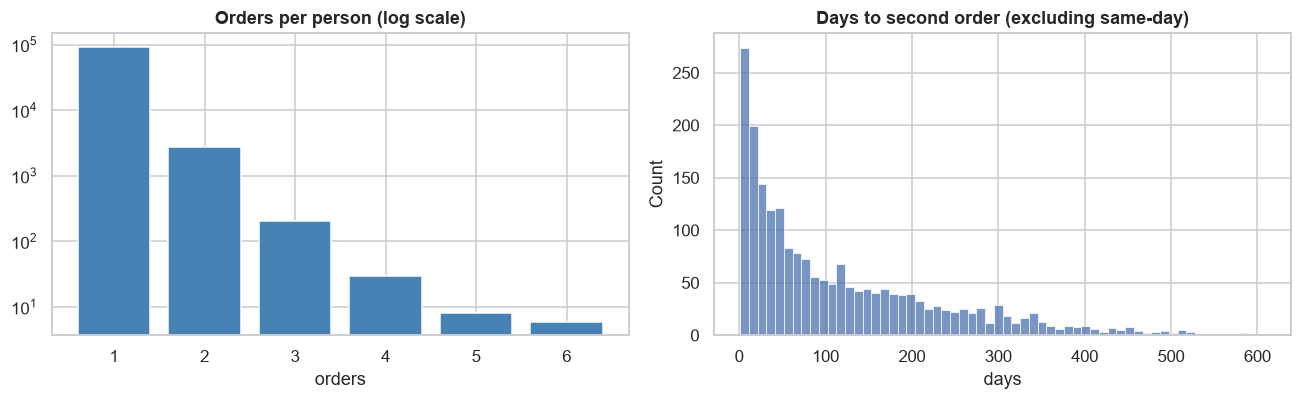

In [8]:
freq = customers["n_orders"].value_counts().sort_index()
repeat_rate = (customers["n_orders"] > 1).mean()
seq = orders.loc[orders["customer_order_seq"] <= 2, ["customer_unique_id", "customer_order_seq", "order_purchase_timestamp"]]
two = seq.pivot(index="customer_unique_id", columns="customer_order_seq", values="order_purchase_timestamp").dropna()
gap = (two[2] - two[1]).dt.total_seconds() / 86400
print(f"persons {len(customers):,}; repeat customers {repeat_rate:.2%}; orders per person: {freq.head(5).to_dict()}")
print(f"time to second order (n={len(gap):,}): same day {(gap < 1).mean():.1%}, within 30 days {(gap <= 30).mean():.1%}, "
      f"median {gap.median():.0f} days, mean {gap.mean():.0f} days")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].bar(freq.index.astype(str)[:6], freq.values[:6], color="steelblue"); ax[0].set_yscale("log")
ax[0].set(title="Orders per person (log scale)", xlabel="orders")
sns.histplot(gap[gap >= 1], bins=60, ax=ax[1]); ax[1].set(title="Days to second order (excluding same-day)", xlabel="days")
plt.tight_layout(); plt.show()

**Interpretation.**
- **Repurchase is rare:** only 3.12% of people (2,997) ever ordered twice. Revenue depends on acquiring new customers, not on retaining them.
- **Second orders are mostly immediate:** among repeaters, 30.9% placed the second order on the same day, which looks like split baskets or a forgotten item (see Q-09). Half came within 30 days (median 28, mean 80 days).
- **Genuine loyalty is therefore even rarer than 3%.** Retention or CRM programmes target a small base. Whether a bad first delivery suppresses repurchase is tested in notebook 05.

### 4.2 Geography: where customers are, what they spend, how fast they are served

,orders,median_order_value,mean_order_value,median_freight_share,median_delivery_days,late_rate,order_share
region,,,,,,,
Sudeste,67706,82.990,131.264,0.171,8.710,0.061,0.686
Sul,14042,89.000,139.150,0.200,12.119,0.059,0.142
Centro-Oeste,5744,89.990,151.543,0.201,13.279,0.065,0.058
Nordeste,9336,99.000,165.541,0.239,17.320,0.127,0.095
Norte,1838,105.000,181.912,0.263,20.157,0.086,0.019


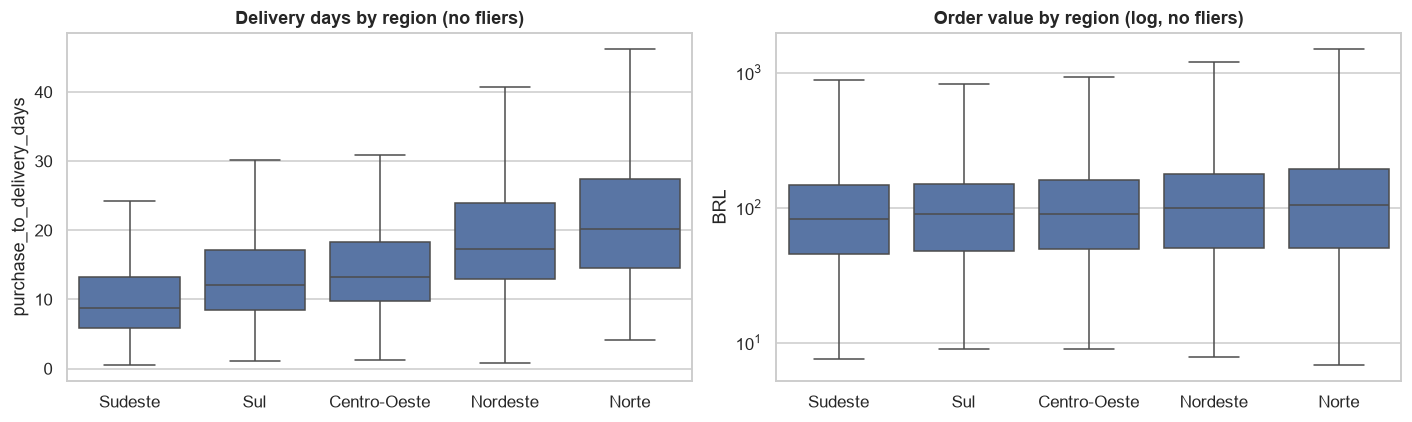

In [9]:
geo = orders[orders["has_items"]].groupby("region").agg(orders=("order_id", "size"),
                                                        median_order_value=("items_price_total", "median"),
                                                        mean_order_value=("items_price_total", "mean"))
fs_region = (orders["items_freight_total"] / (orders["items_price_total"] + orders["items_freight_total"])).groupby(orders["region"]).median()
geo["median_freight_share"] = fs_region
dl = eligible.groupby(eligible["customer_state_std"].map(REGION)).agg(median_delivery_days=("purchase_to_delivery_days", "median"),
                                                                     late_rate=("is_late", "mean"))
geo = geo.join(dl).reindex(REGION_ORDER)
geo["order_share"] = geo["orders"] / geo["orders"].sum()
display(geo)

fig, ax = plt.subplots(1, 2, figsize=(13, 4))
sns.boxplot(data=eligible.assign(region=eligible["customer_state_std"].map(REGION)), x="region", y="purchase_to_delivery_days",
            order=REGION_ORDER, showfliers=False, ax=ax[0]); ax[0].set(title="Delivery days by region (no fliers)", xlabel="")
sns.boxplot(data=orders[orders["has_items"]], x="region", y="items_price_total", order=REGION_ORDER, showfliers=False,
            log_scale=True, ax=ax[1]); ax[1].set(title="Order value by region (log, no fliers)", xlabel="", ylabel="BRL")
plt.tight_layout(); plt.show()

**Interpretation.**
- **Customers:** Sudeste is 68.6% of orders.
- **Basket size:** baskets grow the further a region is from Sudeste. The median order value is 83 BRL in Sudeste against 99 BRL in Nordeste and 105 BRL in Norte.
- **Freight share** rises in the same direction (17% → 26%).
- **Delivery is far slower in the North and North-East:** a median of 17–20 days, against 9 days in Sudeste.
- **Nordeste has the highest late rate (12.7%),** twice Sudeste's (6.1%).

Customers in distant regions appear to consolidate purchases into larger orders and pay relatively more freight. That fits a fixed-cost-per-shipment pattern, though as a hypothesis, not a proven cause. Whether the regional late-rate differences are statistically real is tested in notebook 05.

## 5. Product and category performance

In [10]:
cat_lines = lines.merge(products[["product_id", "category_reporting"]], on="product_id", validate="m:1")
cat = cat_lines.groupby("category_reporting").agg(revenue=("line_price_total", "sum"), units=("quantity", "sum"),
                                                  orders=("order_id", "nunique"), products=("product_id", "nunique"))
cat["avg_unit_price"] = cat["revenue"] / cat["units"]
cat["revenue_share"] = cat["revenue"] / cat["revenue"].sum()
top = cat.nlargest(30, "revenue").reset_index()
print(f"{len(cat)} categories; top 5 carry {cat['revenue_share'].nlargest(5).sum():.1%} of revenue, top 10 {cat['revenue_share'].nlargest(10).sum():.1%}")
print("Spearman(units, avg unit price) across categories:", round(cat[["units", "avg_unit_price"]].corr("spearman").iloc[0, 1], 3))
fig = px.scatter(top, x="units", y="revenue", size="products", color=np.log10(top["avg_unit_price"]), hover_name="category_reporting",
                 log_x=True, log_y=True, color_continuous_scale="Viridis",
                 labels={"color": "log10 avg unit price"}, title="Top 30 categories: units vs revenue (bubble = products)")
fig.update_layout(height=480); fig.show()
display(cat.nlargest(10, "revenue")[["revenue", "revenue_share", "units", "avg_unit_price", "products"]])

74 categories; top 5 carry 39.7% of revenue, top 10 62.4%
Spearman(units, avg unit price) across categories: 0.103


,revenue,revenue_share,units,avg_unit_price,products
category_reporting,,,,,
health_beauty,"1,258,681.340",0.093,9670,130.164,2444
watches_gifts,"1,205,005.680",0.089,5991,201.136,1329
bed_bath_table,"1,036,988.680",0.076,11115,93.296,3029
sports_leisure,"988,048.970",0.073,8641,114.344,2867
computers_accessories,"911,954.320",0.067,7827,116.514,1639
furniture_decor,"729,762.490",0.054,8334,87.564,2657
cool_stuff,"635,290.850",0.047,3796,167.358,789
housewares,"632,248.660",0.047,6964,90.788,2335
auto,"592,720.110",0.044,4235,139.958,1900


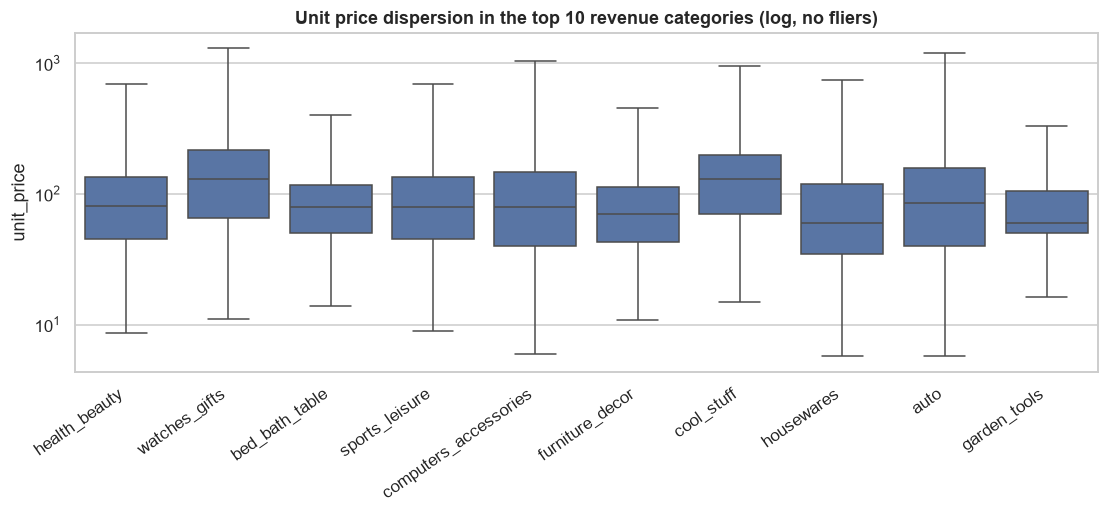

In [11]:
top10 = cat.nlargest(10, "revenue").index
plt.figure(figsize=(12, 4))
sns.boxplot(data=cat_lines[cat_lines["category_reporting"].isin(top10)], x="category_reporting", y="unit_price",
            order=list(top10), showfliers=False, log_scale=True)
plt.xticks(rotation=35, ha="right"); plt.title("Unit price dispersion in the top 10 revenue categories (log, no fliers)"); plt.xlabel("")
plt.show()

**Interpretation.**
- **Category concentration:** the top 5 of 74 categories carry 39.7% of revenue, and the top 10 carry 62.4%.
- **Two routes to revenue:**
  - `health_beauty` and `bed_bath_table` are **volume** categories: the most units, with average unit prices of 130 and 93 BRL.
  - `watches_gifts` and `cool_stuff` are **value** categories: fewer units at 201 and 167 BRL.
- **Volume and price are almost unrelated** across categories (Spearman 0.10), so a category's revenue rank says nothing about its price level.
- **Prices vary hugely within categories** (log-scale boxes spanning about an order of magnitude). Category-level averages hide very different products, so category plans should segment by price band.

## 6. Delivery and reviews
**Question:** how does punctuality and speed relate to the review the customer leaves? (association, not causation)

,orders,mean_score,low_review_rate
delay_bucket,,,
early >14d,34204,4.328,0.089
early 8-14d,35647,4.315,0.088
early 1-7d,17035,4.205,0.101
on the day,1257,4.041,0.123
late 1-3d,1830,3.298,0.320
late 4-7d,1726,2.107,0.675
late 8-14d,1426,1.662,0.804
late >14d,1305,1.721,0.783


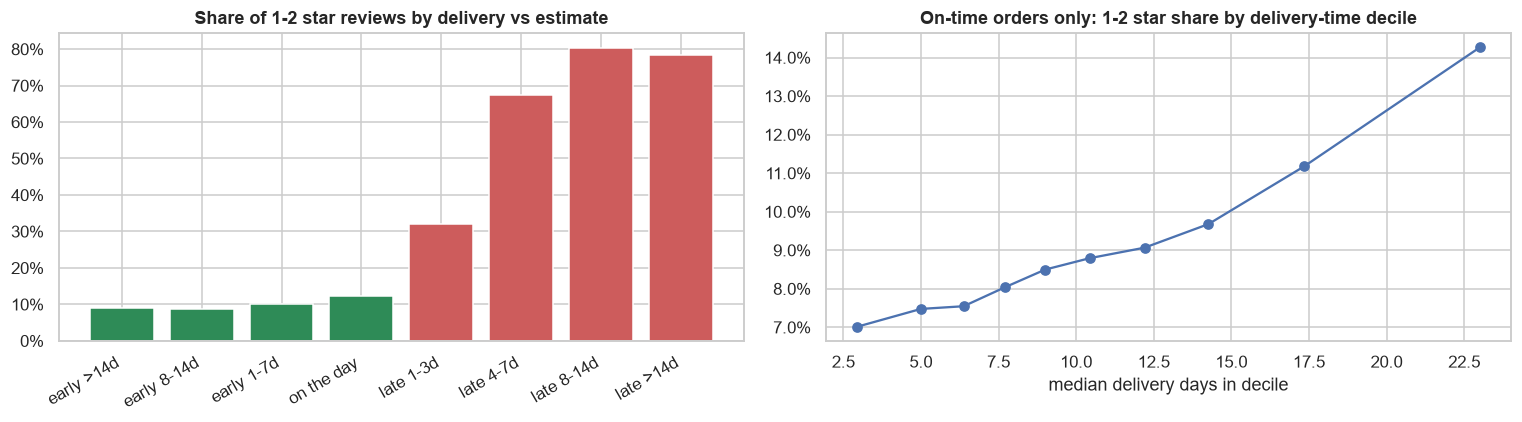

reviews written before delivery: 5.0% of the analysis set; their 1-2 star share 74.2%


In [12]:
bins = [-np.inf, -15, -8, -1, 0, 3, 7, 14, np.inf]
labels = ["early >14d", "early 8-14d", "early 1-7d", "on the day", "late 1-3d", "late 4-7d", "late 8-14d", "late >14d"]
reviewed["delay_bucket"] = pd.cut(reviewed["delivery_vs_estimate_days"], bins=bins, labels=labels)
by_delay = reviewed.groupby("delay_bucket", observed=True).agg(orders=("order_id", "size"), mean_score=("review_score", "mean"),
                                                               low_review_rate=("low_review", "mean"))
display(by_delay)

ontime = reviewed[~reviewed["is_late"]].copy()
ontime["speed_decile"] = pd.qcut(ontime["purchase_to_delivery_days"], 10, labels=False) + 1
by_speed = ontime.groupby("speed_decile").agg(median_days=("purchase_to_delivery_days", "median"), mean_score=("review_score", "mean"),
                                              low_review_rate=("low_review", "mean"))

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].bar(range(len(by_delay)), by_delay["low_review_rate"], color=["seagreen"] * 4 + ["indianred"] * 4)
ax[0].set_xticks(range(len(by_delay)), by_delay.index, rotation=30, ha="right"); ax[0].yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[0].set(title="Share of 1-2 star reviews by delivery vs estimate")
ax[1].plot(by_speed["median_days"], by_speed["low_review_rate"], marker="o"); ax[1].yaxis.set_major_formatter(mtick.PercentFormatter(1))
ax[1].set(title="On-time orders only: 1-2 star share by delivery-time decile", xlabel="median delivery days in decile")
plt.tight_layout(); plt.show()
print(f"reviews written before delivery: {reviewed['dq_review_before_delivery'].mean():.1%} of the analysis set; "
      f"their 1-2 star share {reviewed.loc[reviewed['dq_review_before_delivery'], 'low_review'].mean():.1%}")

**Interpretation.**
- **Early or late:** the 1–2 star share is about 9–10% for early deliveries, 12% on the estimated day, and then jumps to **32% at 1–3 days late, 68% at 4–7 days late, and around 80% beyond a week late.**
- **Speed among on-time orders:** slower deliveries still score a little worse. The 1–2 star share rises steadily from 7.0% in the fastest decile (median 2.9 days) to 14.3% in the slowest (23 days). That effect is much smaller than missing the promised date.
- **Reviews written before delivery** (5% of the set) are 74% negative. They look like complaints about orders that were still missing.

**Takeaway:** keeping the promise matters far more than being fast. The cliff starts at the first day late, so more realistic estimates for slow lanes could protect reviews more than speed improvements would. This is an observational association; notebook 05 quantifies it and adjusts for other order attributes.

## 7. Multivariate view
### 7.1 Rank correlations between order attributes (reviewed, D-06 eligible orders)

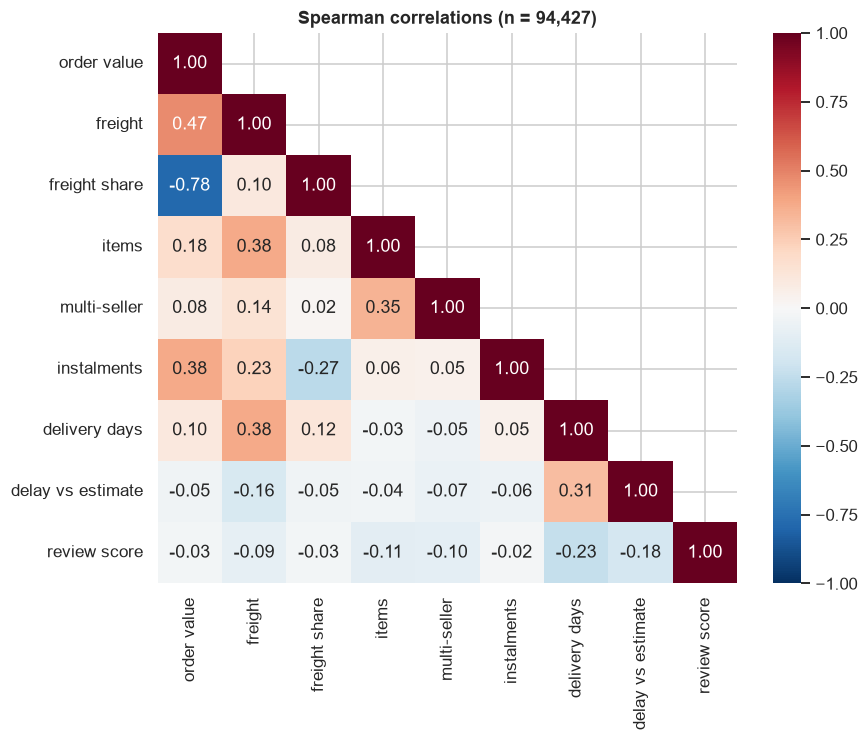

strongest correlations with review score: {'delivery days': -0.235, 'delay vs estimate': -0.177, 'items': -0.108, 'multi-seller': -0.095}


In [13]:
mv = reviewed.assign(freight_share=reviewed["items_freight_total"] / (reviewed["items_price_total"] + reviewed["items_freight_total"]),
                     multi_seller=(reviewed["distinct_sellers"] > 1).astype(int))
cols = {"items_price_total": "order value", "items_freight_total": "freight", "freight_share": "freight share",
        "item_count": "items", "multi_seller": "multi-seller", "max_installments": "instalments",
        "purchase_to_delivery_days": "delivery days", "delivery_vs_estimate_days": "delay vs estimate", "review_score": "review score"}
corr = mv[list(cols)].rename(columns=cols).corr(method="spearman")
plt.figure(figsize=(8.5, 6.5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, mask=np.triu(np.ones_like(corr, bool), 1))
plt.title("Spearman correlations (n = {:,})".format(mv[list(cols)].dropna().shape[0])); plt.show()
print("strongest correlations with review score:", corr["review score"].drop("review score").sort_values(key=abs, ascending=False).round(3).head(4).to_dict())

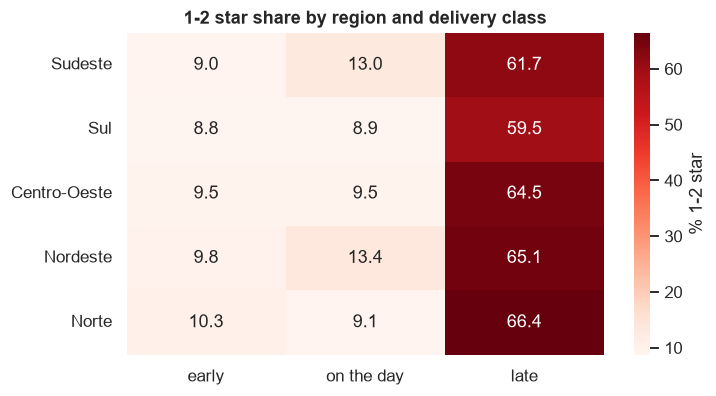

delivery_class,early,on the day,late
region,,,
Sudeste,60012,862,3896
Sul,12617,157,781
Centro-Oeste,5060,74,355
Nordeste,7621,142,1109
Norte,1576,22,146


In [14]:
mv["delivery_class"] = np.select([mv["delivery_vs_estimate_days"] < 0, mv["delivery_vs_estimate_days"] == 0], ["early", "on the day"], "late")
pv = mv.assign(low=mv["low_review"].astype(float)).pivot_table(index="region", columns="delivery_class", values="low", aggfunc="mean").reindex(REGION_ORDER)[["early", "on the day", "late"]]
nn = mv.pivot_table(index="region", columns="delivery_class", values="low_review", aggfunc="size").reindex(REGION_ORDER)[["early", "on the day", "late"]]
plt.figure(figsize=(7, 3.8))
sns.heatmap(pv * 100, annot=True, fmt=".1f", cmap="Reds", cbar_kws={"label": "% 1-2 star"})
plt.title("1-2 star share by region and delivery class"); plt.ylabel(""); plt.xlabel(""); plt.show()
display(nn)

**Interpretation.**
- **What correlates with review score:** delivery days (Spearman -0.24) and delay versus estimate (-0.18) have the strongest monotonic relationships. Smaller ones are the number of items (-0.11) and multi-seller orders (-0.10), which may reflect split shipments where one part arrives later.
- **What doesn't:** order value and freight are almost unrelated to the score.
- **Between attributes:** order value correlates with instalments and freight, as expected (larger baskets are paid in more instalments and cost more to ship).
- **The region × delivery-class heatmap:** within every region, late orders draw 1–2 star reviews **about 60–66% of the time** against about 9–10% for early ones. The regional gaps within a class are small next to the late/early gap.

Regions therefore don't have different tolerances. **Regions score differently mainly because they have different late rates.** This motivates the adjusted model in notebook 05.

## 8. Summary of findings

| # | Finding | Evidence | Business implication |
|---|---|---|---|
| 1 | Order value is log-normal-like with a heavy upper tail | mean 138 vs median 87 BRL; skew 9.7; 8% raw-scale vs 1.5% log-scale outliers | Use the median or log-scale methods; keep large orders (real revenue) |
| 2 | Volume more than doubled year on year; basket size stable | Jan–Aug orders +135%, revenue +137%; monthly AOV 125–152 BRL | Growth is acquisition-led; 2018 volume has plateaued |
| 3 | Black Friday is the only major event; moderate weekly cycle | 1,176 orders on 2017-11-24 (~920 above model); STL weekly strength 0.22 | Model events explicitly in forecasting |
| 4 | Revenue depends on few sellers and products | seller Gini 0.79; top 1% of sellers = 25.7% of revenue | Seller retention is a concentration risk |
| 5 | Repurchase is rare and often immediate | 3.12% repeaters; 31% of second orders the same day | The base is acquisition-driven; true loyalty is below 3% |
| 6 | North and North-East receive slower, later deliveries and pay more freight | median 17–20 vs 9 days; Nordeste late rate 12.7% vs 6.1% | Logistics improvement potential is regional |
| 7 | Lateness, not speed, drives bad reviews | 1–2 star share 9% early → 32% at 1–3 days late → around 80% beyond a week | Realistic promises for slow lanes; act before an order becomes late |

**Limitations:**
- **Observational data:** all relationships are associations.
- **Revenue:** item revenue excludes freight and differs from payments for 303 orders (Q-03).
- **Hours:** shown as recorded; the timezone is unknown (Q-14).
- **Review analyses:** limited to eligible orders with one unshared review (94,430 of 96,470).
- **Coverage:** the trend is based on the 20-month candidate window.